In [1]:
import pandas as pd
from pathlib import Path

path = Path("data/raw/FAOSTAT_data_en_10-8-2026.csv")
df = pd.read_csv(path, encoding="latin-1")

print(df.shape)
print(df.columns.tolist())
df.head()

(192, 15)
['ï»¿Domain Code', 'Domain', 'Area Code (M49)', 'Area', 'Element Code', 'Element', 'Item Code (FAO)', 'Item', 'Year Code', 'Year', 'Unit', 'Value', 'Flag', 'Flag Description', 'Note']


,ï»¿Domain Code,Domain,Area Code (M49),Area,Element Code,Element,Item Code (FAO),Item,Year Code,Year,Unit,Value,Flag,Flag Description,Note
0,QCL,Crops and livestock products,716,Zimbabwe,5312,Area harvested,56,Maize (corn),1961,1961,ha,850000.0,E,Estimated value,NaN
1,QCL,Crops and livestock products,716,Zimbabwe,5412,Yield,56,Maize (corn),1961,1961,kg/ha,1192.9,E,Estimated value,NaN
2,QCL,Crops and livestock products,716,Zimbabwe,5510,Production,56,Maize (corn),1961,1961,t,1014000.0,A,Official value,NaN
3,QCL,Crops and livestock products,716,Zimbabwe,5312,Area harvested,56,Maize (corn),1962,1962,ha,800000.0,E,Estimated value,NaN
4,QCL,Crops and livestock products,716,Zimbabwe,5412,Yield,56,Maize (corn),1962,1962,kg/ha,1117.5,E,Estimated value,NaN


**Data source:** FAOSTAT, Crops and livestock products: Zimbabwe, maize (corn), area harvested, yield and production, 1961-2024. 192 rows x 15 columns (64 years x 3 elements). The first column name carried a hidden byte-order mark, fixed by reading the file with `utf-8-sig`.

In [2]:
# 1. Reload with the correct encoding
df = pd.read_csv(path, encoding="utf-8-sig")
df.columns = df.columns.str.strip()

# 2. Inspect
print(df.columns.tolist())
print(df.isna().sum())
print(df.nunique())
print(df["Flag"].value_counts())
print(df["Year"].min(), df["Year"].max())

['Domain Code', 'Domain', 'Area Code (M49)', 'Area', 'Element Code', 'Element', 'Item Code (FAO)', 'Item', 'Year Code', 'Year', 'Unit', 'Value', 'Flag', 'Flag Description', 'Note']
Domain Code           0
Domain                0
Area Code (M49)       0
Area                  0
Element Code          0
Element               0
Item Code (FAO)       0
Item                  0
Year Code             0
Year                  0
Unit                  0
Value                 0
Flag                  0
Flag Description      0
Note                184
dtype: int64
Domain Code           1
Domain                1
Area Code (M49)       1
Area                  1
Element Code          3
Element               3
Item Code (FAO)       1
Item                  1
Year Code            64
Year                 64
Unit                  3
Value               190
Flag                  3
Flag Description      3
Note                  1
dtype: int64
Flag
A    165
E     16
X     11
Name: count, dtype: int64
1961 2024


**Quality checks:** No missing values in Value, Year, Unit or Flag; only Note has gaps (184 of 192 empty). Domain Code, Domain, Area Code, Area, Item Code and Item each have a single unique value, so they carry no information (Element, Element Code and Unit vary only with the three elements; Year Code mirrors Year). Flags: 165 official (A), 16 estimated (E), 11 external-organisation figures (X). The 8 rows with a note are all "Unofficial figure" (area for 1966-69 and 2009; production for 1967, 1969 and 2009).

In [3]:
# 3. Keep only what's useful and pivot to one row per year
wide = df.pivot(index="Year", columns="Element", values="Value")
wide = wide.rename(columns={
    "Area harvested": "area_harvested_ha",
    "Production": "production_t",
    "Yield": "yield_kg_ha",
}).reset_index()

# 4. Keep the quality flag for yield
yield_flag = df[df["Element"] == "Yield"].set_index("Year")["Flag"].rename("yield_flag")
wide = wide.join(yield_flag, on="Year")

# 5. Sanity check: yield should equal production / area
wide["yield_check"] = wide["production_t"] / wide["area_harvested_ha"] * 1000
wide["diff"] = (wide["yield_kg_ha"] - wide["yield_check"]).abs()

print(wide.shape)
wide.head(10)

(64, 7)


,Year,area_harvested_ha,production_t,yield_kg_ha,yield_flag,yield_check,diff
0,1961,850000.0,1014000.0,1192.9,E,1192.941176,0.041176
1,1962,800000.0,894000.0,1117.5,E,1117.500000,0.000000
2,1963,750000.0,720000.0,960.0,E,960.000000,0.000000
3,1964,750000.0,716000.0,954.7,E,954.666667,0.033333
4,1965,750000.0,822000.0,1096.0,E,1096.000000,0.000000
5,1966,791574.0,900000.0,1137.0,E,1136.975191,0.024809
6,1967,855315.0,1517590.0,1774.3,X,1774.305373,0.005373
7,1968,736962.0,975436.0,1323.6,E,1323.590633,0.009367
8,1969,890934.0,1571520.0,1763.9,X,1763.901703,0.001703
9,1970,902810.0,1085327.0,1202.2,A,1202.165461,0.034539


**Reshaped** from long to wide: one row per year (64 rows) with area harvested, production and yield. Consistency check: yield should equal production / area x 1000. In the first ten rows the two agree to within 0.05 kg/ha, which is rounding.

In [4]:
# What do the notes say?
print(df.loc[df["Note"].notna(), ["Year", "Element", "Value", "Flag", "Note"]])

# What do the flags mean?
print(df[["Flag", "Flag Description"]].drop_duplicates())

# Summary statistics
print(wide[["area_harvested_ha", "production_t", "yield_kg_ha"]].describe())

# Best and worst years for yield
print(wide.nsmallest(8, "yield_kg_ha")[["Year", "yield_kg_ha", "yield_flag"]])
print(wide.nlargest(5, "yield_kg_ha")[["Year", "yield_kg_ha", "yield_flag"]])

     Year         Element      Value Flag               Note
15   1966  Area harvested   791574.0    X  Unofficial figure
18   1967  Area harvested   855315.0    X  Unofficial figure
20   1967      Production  1517590.0    X  Unofficial figure
21   1968  Area harvested   736962.0    X  Unofficial figure
24   1969  Area harvested   890934.0    X  Unofficial figure
26   1969      Production  1571520.0    X  Unofficial figure
144  2009  Area harvested  1508000.0    X  Unofficial figure
146  2009      Production   700000.0    X  Unofficial figure
   Flag                  Flag Description
0     E                   Estimated value
2     A                    Official value
15    X  Value from external organization
       area_harvested_ha  production_t  yield_kg_ha
count       6.400000e+01  6.400000e+01    64.000000
mean        1.186802e+06  1.381953e+06  1199.104687
std         3.107446e+05  5.888488e+05   485.899875
min         7.369620e+05  3.619000e+05   286.700000
25%         9.693062e+0

**Yield summary:** mean 1,199 kg/ha (median 1,180), from 287 (2008) to 2,311 (1972). The lowest years are 2008, 1992, 2016, 2002, 2009, 2015, 1995 and 2005. Most match known drought seasons, but 2008 and 2009 coincide with economic disruption and are treated as possible non-climate outliers. The five highest years (1972, 1985, 1981, 1974, 1986) are all officially reported.

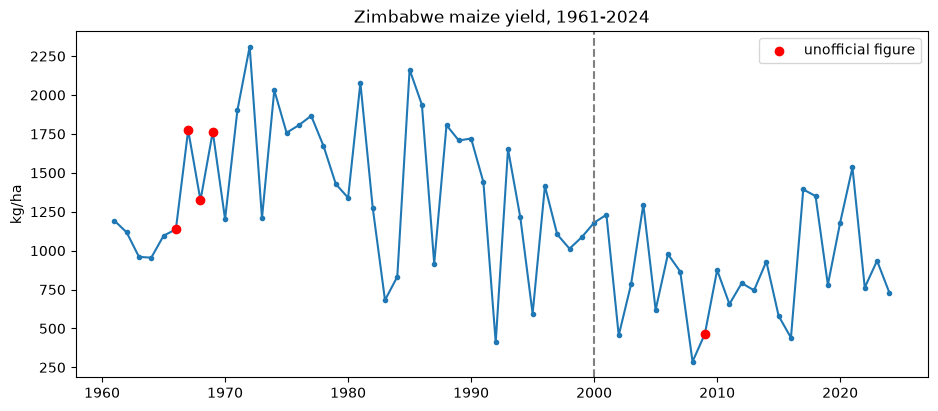

In [5]:
flags = (df.pivot(index="Year", columns="Element", values="Flag")
           .rename(columns={"Area harvested": "flag_area",
                            "Production": "flag_production",
                            "Yield": "flag_yield"})
           .reset_index())

clean = wide.drop(columns=["yield_check", "diff", "yield_flag"]).merge(flags, on="Year")
flag_cols = ["flag_area", "flag_production", "flag_yield"]
clean["any_unofficial"] = (clean[flag_cols] == "X").any(axis=1)
clean["any_estimated"] = (clean[flag_cols] == "E").any(axis=1)

import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(clean["Year"], clean["yield_kg_ha"], marker="o", ms=3)
bad = clean[clean["any_unofficial"]]
ax.scatter(bad["Year"], bad["yield_kg_ha"], color="red", zorder=3, label="unofficial figure")
ax.axvline(2000, ls="--", color="grey")
ax.set_title("Zimbabwe maize yield, 1961-2024")
ax.set_ylabel("kg/ha")
ax.legend()
plt.show()

out = Path("data/processed")
out.mkdir(parents=True, exist_ok=True)
clean.to_csv(out / "maize_zimbabwe_clean.csv", index=False)

**Observation:** Yields peak in the early 1970s and decline thereafter, with sharp dips in drought seasons (e.g. 1992, 2002, 2015-16) and a partial recovery after 2017. Red points mark years with unofficial figures (1966-69 and 2009). The long-term decline means rainfall alone cannot explain yield.

In [6]:
import pandas as pd
from pathlib import Path

rain_path = Path("data/raw/zim_climate_cru.xlsx")

xl = pd.ExcelFile(rain_path)
print(xl.sheet_names)

for s in xl.sheet_names:
    print("-----", s)
    sheet = xl.parse(s)
    print(sheet.shape)
    print(sheet.head(10))

['pr', 'tas']
----- pr
(1, 1502)
  code      name  1901-01  1901-02  1901-03  1901-04  1901-05  1901-06  \
0  ZWE  Zimbabwe   175.27   186.67   118.39    32.67     4.66     6.88   

   1901-07  1901-08  ...  2025-03  2025-04  2025-05  2025-06  2025-07  \
0      0.2     2.27  ...    92.24    46.55      7.1     3.31      2.9   

   2025-08  2025-09  2025-10  2025-11  2025-12  
0      1.3     5.94    31.22      102   203.92  

[1 rows x 1502 columns]
----- tas
(1, 1502)
  code      name  1901-01  1901-02  1901-03  1901-04  1901-05  1901-06  \
0  ZWE  Zimbabwe    24.51    23.71    23.02    21.57    18.34    15.19   

   1901-07  1901-08  ...  2025-03  2025-04  2025-05  2025-06  2025-07  \
0    15.11    17.83  ...    23.56    22.23    18.87    17.32    16.49   

   2025-08  2025-09  2025-10  2025-11  2025-12  
0    19.03    22.97    24.47     24.2    23.83  

[1 rows x 1502 columns]


**Climate source:** World Bank Climate Change Knowledge Portal, CRU 0.5-degree, Zimbabwe national mean, monthly precipitation (mm) and surface air temperature (deg C), 1901-2025. Each sheet is a single row of 1,500 monthly columns (125 years x 12 months), so it needs reshaping before use.

In [7]:
def to_long(sheet_name, value_name):
    s = xl.parse(sheet_name).drop(columns=["code", "name"])
    long = s.melt(var_name="month", value_name=value_name)
    long["date"] = pd.to_datetime(long["month"], format="%Y-%m")
    return long.drop(columns="month")

monthly = to_long("pr", "rain_mm").merge(to_long("tas", "temp_c"), on="date")
monthly["year"] = monthly["date"].dt.year
monthly["month"] = monthly["date"].dt.month

# Oct-Dec belong to the NEXT year's harvest
monthly["harvest_year"] = monthly["year"] + (monthly["month"] >= 10).astype(int)

# Growing season: October to March
season = monthly[monthly["month"].isin([10, 11, 12, 1, 2, 3])]
rain = (season.groupby("harvest_year")
        .agg(season_rain_mm=("rain_mm", "sum"),
             season_temp_c=("temp_c", "mean"),
             n_months=("rain_mm", "count"))
        .reset_index())

# Keep only complete seasons (all 6 months present)
rain = rain[rain["n_months"] == 6].drop(columns="n_months")

# Mid-season rainfall (Dec-Feb), when maize is most sensitive
mid = (monthly[monthly["month"].isin([12, 1, 2])]
       .groupby("harvest_year")["rain_mm"].sum().rename("rain_dec_feb_mm"))
rain = rain.merge(mid, on="harvest_year", how="left")

print(rain.shape)
rain.head()

(124, 4)


,harvest_year,season_rain_mm,season_temp_c,rain_dec_feb_mm
0,1902,802.67,23.400000,531.08
1,1903,474.36,23.940000,277.44
2,1904,689.94,23.031667,429.55
3,1905,614.00,23.378333,434.17
4,1906,605.58,24.176667,498.91


**Growing season:** October to March. FAOSTAT years are harvest years, so October-December are assigned to the following year (the 1991/92 season is labelled 1992). Only complete six-month seasons were kept (124 seasons, 1902-2025); 1901 and 2026 were dropped as incomplete. Dec-Feb rainfall was added as a mid-season measure.

In [8]:
maize = pd.read_csv("data/processed/maize_zimbabwe_clean.csv")
merged = maize.merge(rain, left_on="Year", right_on="harvest_year", how="left").drop(columns="harvest_year")

print(merged.shape, merged["season_rain_mm"].isna().sum())
print(merged[["season_rain_mm", "season_temp_c"]].describe())

# Driest seasons: do they line up with the low-yield years?
print(merged.nsmallest(8, "season_rain_mm")[["Year", "season_rain_mm", "yield_kg_ha"]])

# First look at relationships
print(merged[["yield_kg_ha", "season_rain_mm", "rain_dec_feb_mm", "season_temp_c"]].corr().round(2))

merged.to_csv("data/processed/maize_rain_merged.csv", index=False)

(64, 12) 0
       season_rain_mm  season_temp_c
count       64.000000      64.000000
mean       632.690156      24.191823
std        140.383153       0.571955
min        356.760000      23.021667
25%        548.050000      23.787917
50%        625.870000      24.254167
75%        718.832500      24.578333
max        979.380000      25.533333
    Year  season_rain_mm  yield_kg_ha
31  1992          356.76        410.8
12  1973          381.51       1208.8
7   1968          388.49       1323.6
55  2016          409.89        440.5
22  1983          416.64        682.1
34  1995          431.95        594.9
26  1987          448.23        917.3
41  2002          454.39        455.4
                 yield_kg_ha  season_rain_mm  rain_dec_feb_mm  season_temp_c
yield_kg_ha             1.00            0.53             0.52          -0.63
season_rain_mm          0.53            1.00             0.95          -0.36
rain_dec_feb_mm         0.52            0.95             1.00          -0.36
season

**Merge:** joined on harvest year; 64 rows, no missing rainfall. Seasonal rainfall averages 633 mm (SD 140, range 357-979). Driest seasons: 1992, 1973, 1968, 2016, 1983, 1995, 1987, 2002. 1992, 2016, 1995 and 2002 are known drought seasons and have low yields (411, 441, 595 and 455 kg/ha), which supports the harvest-year alignment. Similarly dry seasons in the 1960s-80s gave much higher yields (1968: 1,324; 1973: 1,209; 1987: 917 kg/ha), an early sign of the shifting baseline. Correlation with yield: rainfall 0.53, temperature -0.63. Dec-Feb rainfall correlates 0.95 with seasonal rainfall, so it is not used alongside it. The temperature correlation is partly a shared trend (warming vs. falling yields).

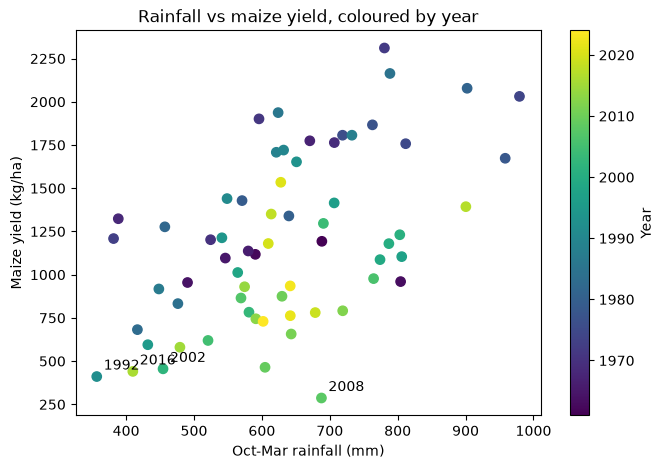

In [9]:
import matplotlib.pyplot as plt

m = merged.copy()

fig, ax = plt.subplots(figsize=(7.5, 5))
sc = ax.scatter(m["season_rain_mm"], m["yield_kg_ha"], c=m["Year"], cmap="viridis", s=45)
plt.colorbar(sc, label="Year")
for y in (1992, 2002, 2008, 2016):
    r = m[m["Year"] == y].iloc[0]
    ax.annotate(str(y), (r["season_rain_mm"], r["yield_kg_ha"]), xytext=(5, 5), textcoords="offset points")
ax.set_xlabel("Oct-Mar rainfall (mm)")
ax.set_ylabel("Maize yield (kg/ha)")
ax.set_title("Rainfall vs maize yield, coloured by year")
plt.show()

**Observation:** More rain goes with higher yield, but the colours show a shifting baseline: for the same rainfall, recent years (green/yellow) sit well below the 1960s-80s (purple/blue). 2008 is far below the pattern for its rainfall (about 690 mm, 287 kg/ha).

In [10]:
import statsmodels.api as sm

m["year_c"] = m["Year"] - m["Year"].mean()

def fit(cols):
    X = sm.add_constant(m[cols])
    return sm.OLS(m["yield_kg_ha"], X).fit()

for cols in (["season_rain_mm"],
             ["season_rain_mm", "year_c"],
             ["season_rain_mm", "season_temp_c", "year_c"]):
    r = fit(cols)
    print(cols, "| R2:", round(r.rsquared, 2), "| adj R2:", round(r.rsquared_adj, 2))

print(fit(["season_rain_mm", "season_temp_c", "year_c"]).summary().tables[1])

['season_rain_mm'] | R2: 0.29 | adj R2: 0.27
['season_rain_mm', 'year_c'] | R2: 0.51 | adj R2: 0.49
['season_rain_mm', 'season_temp_c', 'year_c'] | R2: 0.54 | adj R2: 0.52
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const           6100.1296   2942.421      2.073      0.042     214.411     1.2e+04
season_rain_mm     1.4681      0.343      4.285      0.000       0.783       2.153
season_temp_c   -240.9848    117.192     -2.056      0.044    -475.403      -6.566
year_c            -7.2159      3.366     -2.144      0.036     -13.948      -0.484


**Result:** Rainfall alone explains about 27% of yield variation (adjusted R2 0.27). Adding a time trend raises it to 0.49, so the long-term decline matters as much as seasonal weather. Full model: +1.47 kg/ha per mm of rain (p < 0.001), -241 kg/ha per deg C (p = 0.044), -7.2 kg/ha per year (p = 0.036).

In [11]:
cols = ["season_rain_mm", "season_temp_c", "year_c"]

def fit_df(d, cols):
    return sm.OLS(d["yield_kg_ha"], sm.add_constant(d[cols])).fit()

variants = {
    "all years": m,
    "excl. 2008": m[m["Year"] != 2008],
    "excl. unofficial": m[~m["any_unofficial"]],
    "excl. both": m[(m["Year"] != 2008) & (~m["any_unofficial"])],
}

rows = []
for name, d in variants.items():
    r = fit_df(d, cols)
    rows.append({"sample": name, "n": int(r.nobs),
                 "rain_coef": r.params["season_rain_mm"], "rain_p": r.pvalues["season_rain_mm"],
                 "temp_coef": r.params["season_temp_c"], "temp_p": r.pvalues["season_temp_c"],
                 "year_coef": r.params["year_c"], "adj_R2": r.rsquared_adj})
print(pd.DataFrame(rows).round(3))

# Which years does the model get most wrong?
m["resid"] = fit_df(m, cols).resid
print(m.reindex(m["resid"].abs().sort_values(ascending=False).index)
        .head(8)[["Year", "yield_kg_ha", "resid"]])

             sample   n  rain_coef  rain_p  temp_coef  temp_p  year_coef  \
0         all years  64      1.468     0.0   -240.985   0.044     -7.216   
1        excl. 2008  63      1.479     0.0   -264.214   0.021     -6.074   
2  excl. unofficial  59      1.473     0.0   -245.756   0.046     -6.258   
3        excl. both  58      1.487     0.0   -269.323   0.021     -5.047   

   adj_R2  
0   0.517  
1   0.546  
2   0.507  
3   0.541  
    Year  yield_kg_ha       resid
47  2008        286.7 -872.116817
2   1963        960.0 -864.619040
60  2021       1534.4  670.159547
25  1986       1937.3  615.768465
24  1985       2163.7  569.923849
10  1971       1901.1  515.913504
32  1993       1652.6  491.665849
11  1972       2311.0  475.900981


**Robustness:** The rainfall coefficient stays between 1.47 and 1.49 across four samples (all years; excluding 2008; excluding unofficial years; excluding both). Temperature is negative in every sample (p between 0.021 and 0.046). Largest residuals in this model: 2008 (-872 kg/ha) and 1963 (-865; an estimated-flag year).

In [12]:
m["post2000"] = (m["Year"] > 2000).astype(int)   # 1 for harvest years 2001-2024, 0 for 1961-2000

specs = {
    "rain+temp+trend":          ["season_rain_mm", "season_temp_c", "year_c"],
    "rain+temp+post2000":       ["season_rain_mm", "season_temp_c", "post2000"],
    "rain+temp+trend+post2000": ["season_rain_mm", "season_temp_c", "year_c", "post2000"],
}
for name, c in specs.items():
    r = fit_df(m, c)
    print(f"{name:28s} adj R2 = {r.rsquared_adj:.3f} | rain = {r.params['season_rain_mm']:.2f} | temp = {r.params['season_temp_c']:.0f}")

# Drop all estimated (E) and unofficial (X) years
good = m[~m["any_estimated"] & ~m["any_unofficial"]]
r = fit_df(good, specs["rain+temp+post2000"])
print("\nOfficial-only sample, n =", int(r.nobs))
print(r.summary().tables[1])

rain+temp+trend              adj R2 = 0.517 | rain = 1.47 | temp = -241
rain+temp+post2000           adj R2 = 0.565 | rain = 1.53 | temp = -191
rain+temp+trend+post2000     adj R2 = 0.558 | rain = 1.52 | temp = -198

Official-only sample, n = 54
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const           5858.1643   2578.397      2.272      0.027     679.301     1.1e+04
season_rain_mm     1.5707      0.333      4.721      0.000       0.902       2.239
season_temp_c   -226.6201    103.248     -2.195      0.033    -434.000     -19.240
post2000        -378.7580    110.736     -3.420      0.001    -601.177    -156.339


**Model choice:** A step change fits better than a linear trend (adjusted R2 0.565 vs 0.517), and adding both does not help. On the official-only sample (n = 54): rainfall +1.57 kg/ha per mm (95% CI 0.90-2.24), post-2000 shift -379 kg/ha (p = 0.001). The step bundles everything that changed after the cutoff (policy, economy, inputs), so it is described as a "shift", not attributed to a cause.

                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const           5004.2422   2232.405      2.242      0.025     628.809    9379.676
season_rain_mm     1.5264      0.285      5.354      0.000       0.968       2.085
season_temp_c   -191.2728     89.176     -2.145      0.032    -366.055     -16.491
post2000        -383.0905    109.867     -3.487      0.000    -598.425    -167.756
1995 adjR2 0.609 | shift -506 | rain 1.87
1998 adjR2 0.597 | shift -445 | rain 1.69
2000 adjR2 0.565 | shift -383 | rain 1.53
2002 adjR2 0.534 | shift -320 | rain 1.48
2005 adjR2 0.536 | shift -298 | rain 1.44


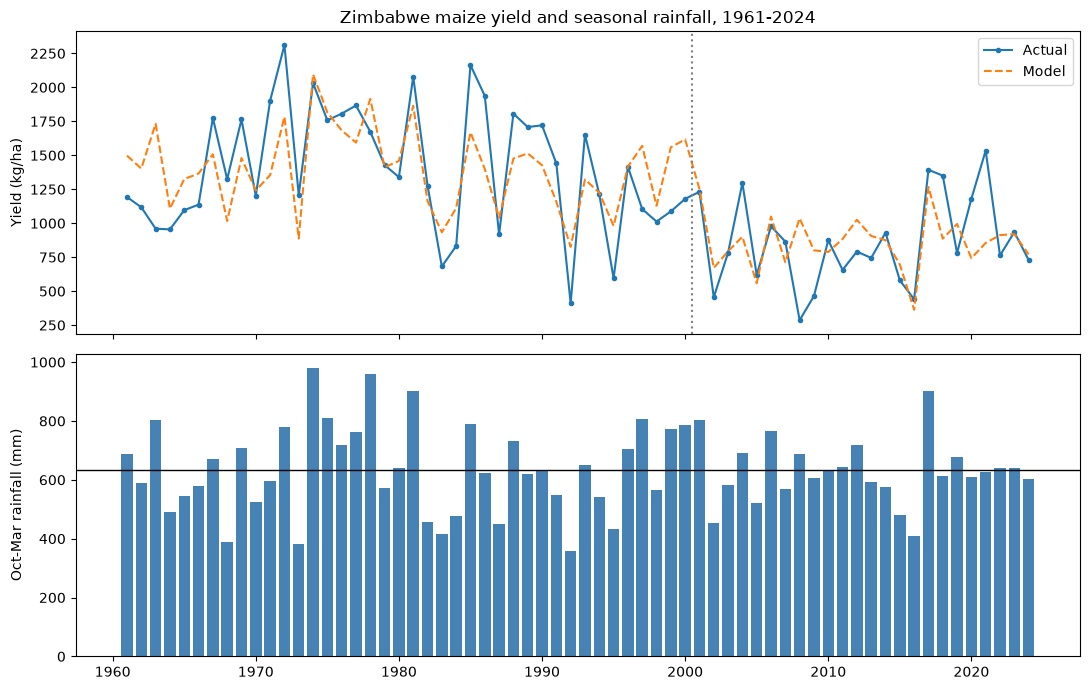

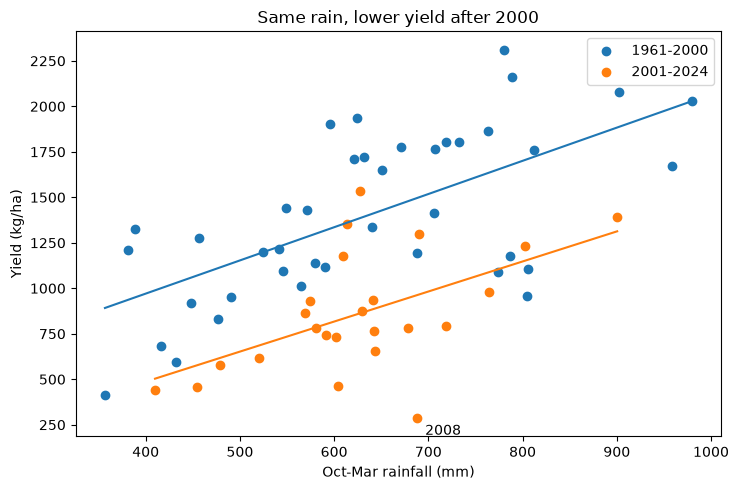

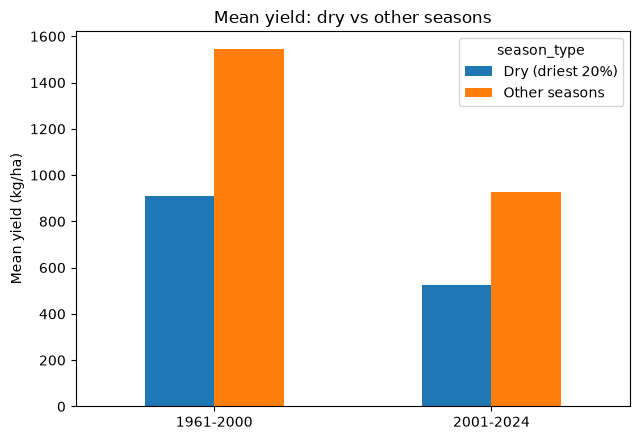

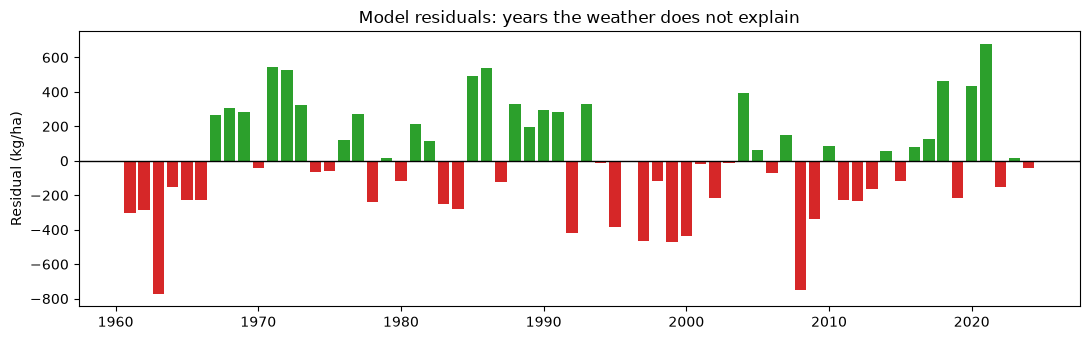

In [13]:
import numpy as np
from pathlib import Path
Path("figures").mkdir(exist_ok=True)

final_cols = ["season_rain_mm", "season_temp_c", "post2000"]
final = fit_df(m, final_cols)
m["fitted"] = final.fittedvalues

# 1. Standard errors robust to autocorrelation (time-series data)
robust = sm.OLS(m["yield_kg_ha"], sm.add_constant(m[final_cols])).fit(
    cov_type="HAC", cov_kwds={"maxlags": 2})
print(robust.summary().tables[1])

# 2. Does the result depend on the 2000 cutoff?
for cut in (1995, 1998, 2000, 2002, 2005):
    d = m.assign(post=(m["Year"] > cut).astype(int))
    r = fit_df(d, ["season_rain_mm", "season_temp_c", "post"])
    print(cut, "adjR2", round(r.rsquared_adj, 3),
          "| shift", round(r.params["post"]), "| rain", round(r.params["season_rain_mm"], 2))

# Figure 1: yield (actual vs model) above seasonal rainfall
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
a1.plot(m["Year"], m["yield_kg_ha"], marker="o", ms=3, label="Actual")
a1.plot(m["Year"], m["fitted"], ls="--", label="Model")
a1.axvline(2000.5, color="grey", ls=":")
a1.set_ylabel("Yield (kg/ha)"); a1.legend()
a1.set_title("Zimbabwe maize yield and seasonal rainfall, 1961-2024")
a2.bar(m["Year"], m["season_rain_mm"], color="steelblue")
a2.axhline(m["season_rain_mm"].mean(), color="k", lw=1)
a2.set_ylabel("Oct-Mar rainfall (mm)")
plt.tight_layout(); plt.savefig("figures/01_timeseries.png", dpi=150); plt.show()

# Figure 2: rainfall-yield relationship before and after 2000
fig, ax = plt.subplots(figsize=(7.5, 5))
for flag, label, col in ((0, "1961-2000", "tab:blue"), (1, "2001-2024", "tab:orange")):
    d = m[m["post2000"] == flag]
    ax.scatter(d["season_rain_mm"], d["yield_kg_ha"], color=col, label=label)
    b = np.polyfit(d["season_rain_mm"], d["yield_kg_ha"], 1)
    xs = np.linspace(d["season_rain_mm"].min(), d["season_rain_mm"].max(), 50)
    ax.plot(xs, np.polyval(b, xs), color=col)
r08 = m[m["Year"] == 2008].iloc[0]
ax.annotate("2008", (r08["season_rain_mm"], r08["yield_kg_ha"]), xytext=(6, -12), textcoords="offset points")
ax.set_xlabel("Oct-Mar rainfall (mm)"); ax.set_ylabel("Yield (kg/ha)")
ax.set_title("Same rain, lower yield after 2000"); ax.legend()
plt.tight_layout(); plt.savefig("figures/02_scatter_periods.png", dpi=150); plt.show()

# Figure 3: dry seasons vs other seasons, by period
thr = m["season_rain_mm"].quantile(0.2)
m["season_type"] = np.where(m["season_rain_mm"] <= thr, "Dry (driest 20%)", "Other seasons")
summ = m.groupby(["post2000", "season_type"])["yield_kg_ha"].mean().unstack()
summ.index = ["1961-2000", "2001-2024"]
summ.plot(kind="bar", rot=0, figsize=(6.5, 4.5))
plt.ylabel("Mean yield (kg/ha)"); plt.title("Mean yield: dry vs other seasons")
plt.tight_layout(); plt.savefig("figures/03_dry_vs_other.png", dpi=150); plt.show()

# Figure 4: what the model cannot explain
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(m["Year"], final.resid, color=np.where(final.resid > 0, "tab:green", "tab:red"))
ax.axhline(0, color="k", lw=1)
ax.set_ylabel("Residual (kg/ha)"); ax.set_title("Model residuals: years the weather does not explain")
plt.tight_layout(); plt.savefig("figures/04_residuals.png", dpi=150); plt.show()

**Autocorrelation check:** With standard errors robust to autocorrelation (HAC, 2 lags): rainfall +1.53 kg/ha per mm (95% CI 0.97-2.09, p < 0.001); temperature -191 kg/ha per deg C (CI -366 to -16, p = 0.032); post-2000 shift -383 kg/ha (CI -598 to -168, p < 0.001). The rainfall result holds up. The five-cutoff check in this cell is extended to 1985-2010 below.

**Figure 1:** The model (dashed) follows the long-term decline and most of the dips, with a step down after 2000. It understates the severity of the worst droughts (1992: about 820 predicted vs 411 actual) and the 1970s-80s peaks (1972, 1985-86), and overpredicts 1963 and 1997-2000. 2008 is its biggest miss (actual 287; model about 1,030 kg/ha). In the lower panel, the driest seasons (1992, 2016, 1983, 1995) line up with the lowest yields.

**Figure 2:** The two lines are roughly parallel, so rainfall raises yield by a similar amount in both periods. At the same rainfall the 2001-2024 line sits roughly 500 kg/ha below the 1961-2000 line (the regression shift, which also controls for temperature, is -383 kg/ha). 2008 lies far below even the post-2000 line.

**Figure 3:** Dry seasons (driest 20%) yield roughly 40% less than other seasons in both periods: about 900 vs 1,550 kg/ha in 1961-2000, and about 525 vs 925 kg/ha in 2001-2024. The absolute loss is smaller after 2000 only because the baseline is lower; the proportional drought penalty looks similar.

**Figure 4:** Green bars are years better than the weather predicts, red bars worse. The largest negative residuals are 1963 (about -770, an estimated-flag year) and 2008 (about -750). The largest positive are 2021 (about +680) and 1971-72 and 1985-86 (about +500 to +550). Residuals are mostly negative in 1997-2000 (about -450 in 1997, 1999 and 2000), just before the cutoff, which is consistent with the sweep favouring an earlier break.

 cutoff  adj_R2    shift  rain
   1985   0.498 -174.447 1.329
   1986   0.516 -253.211 1.382
   1987   0.516 -250.315 1.421
   1988   0.534 -299.789 1.428
   1989   0.548 -362.528 1.502
   1990   0.573 -439.994 1.576
   1991   0.599 -485.670 1.638
   1992   0.580 -441.065 1.695
   1993   0.610 -489.730 1.728
   1994   0.623 -527.149 1.815
   1995   0.609 -505.768 1.873
   1996   0.618 -510.415 1.836
   1997   0.594 -450.540 1.686
   1998   0.597 -444.974 1.688
   1999   0.579 -407.763 1.597
   2000   0.565 -383.090 1.526
   2001   0.554 -363.127 1.459
   2002   0.534 -320.087 1.482
   2003   0.527 -293.677 1.465
   2004   0.538 -314.747 1.445
   2005   0.536 -297.950 1.436
   2006   0.529 -274.339 1.374
   2007   0.531 -278.117 1.374
   2008   0.501 -184.178 1.316
   2009   0.491 -136.529 1.291
   2010   0.492 -141.165 1.284


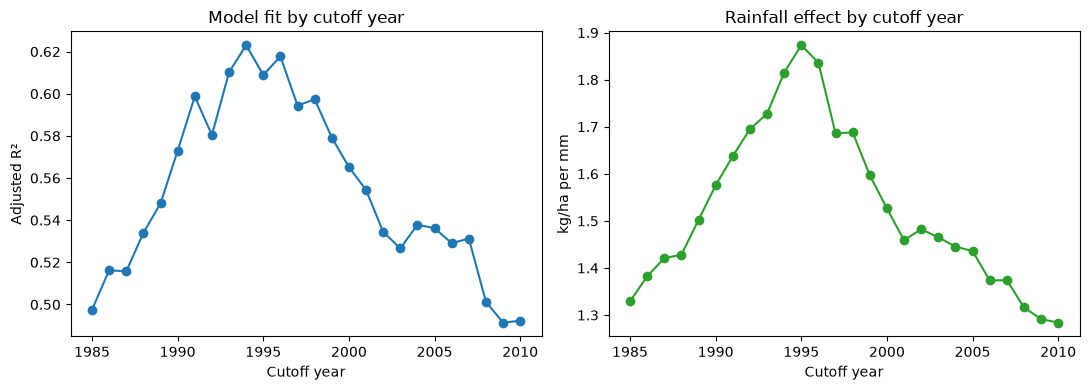

In [14]:
rows = []
for cut in range(1985, 2011):
    d = m.assign(post=(m["Year"] > cut).astype(int))
    r = fit_df(d, ["season_rain_mm", "season_temp_c", "post"])
    rows.append({"cutoff": cut, "adj_R2": r.rsquared_adj,
                 "shift": r.params["post"], "rain": r.params["season_rain_mm"]})
sweep = pd.DataFrame(rows)
print(sweep.round(3).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(sweep["cutoff"], sweep["adj_R2"], marker="o")
ax[0].set_title("Model fit by cutoff year")
ax[0].set_xlabel("Cutoff year"); ax[0].set_ylabel("Adjusted R²")
ax[1].plot(sweep["cutoff"], sweep["rain"], marker="o", color="tab:green")
ax[1].set_title("Rainfall effect by cutoff year")
ax[1].set_xlabel("Cutoff year"); ax[1].set_ylabel("kg/ha per mm")
plt.tight_layout()
plt.savefig("figures/05_cutoff_sensitivity.png", dpi=150)
plt.show()

**Sensitivity to the break year:** Model fit peaks at a cutoff of 1994 (adjusted R2 0.623), with a broad plateau of roughly 0.58-0.62 across 1991-1998, then declines; 2000 gives 0.565. The decline in yields therefore appears to begin in the early-to-mid 1990s, with no single sharply preferred year. The rainfall effect ranges from 1.28 to 1.87 kg/ha per mm across the cutoffs tested, 1985-2010 (1.53 at 2000). Because the best cutoff is selected after seeing the fit, p-values from it are optimistic; 2000 is kept as the main specification and the sweep is reported as a sensitivity check.

In [15]:
# Does 2008 drive the results? Add a 2008 dummy to the main model and compare.
# Same HAC standard errors (2 lags) as the main model above.
m["is2008"] = (m["Year"] == 2008).astype(int)
base_cols = ["season_rain_mm", "season_temp_c", "post2000"]

def hac_fit(d, cols):
    return sm.OLS(d["yield_kg_ha"], sm.add_constant(d[cols])).fit(
        cov_type="HAC", cov_kwds={"maxlags": 2})

def summarise(name, r):
    ci = r.conf_int()
    out = {"model": name, "n": int(r.nobs), "adj_R2": r.rsquared_adj}
    for v, label in (("season_rain_mm", "rain"), ("season_temp_c", "temp"), ("post2000", "post2000")):
        out[f"{label}_coef"] = r.params[v]
        out[f"{label}_ci_low"] = ci.loc[v, 0]
        out[f"{label}_ci_high"] = ci.loc[v, 1]
        out[f"{label}_p"] = r.pvalues[v]
    out["effect_of_2008"] = r.params.get("is2008", np.nan)
    return out

main_fit = hac_fit(m, base_cols)
dummy_fit = hac_fit(m, base_cols + ["is2008"])
compare = pd.DataFrame([summarise("main model", main_fit),
                        summarise("with 2008 dummy", dummy_fit)]).set_index("model")
print(compare.round(3).T.to_string())

model             main model  with 2008 dummy
n                     64.000           64.000
adj_R2                 0.565            0.601
rain_coef              1.526            1.528
rain_ci_low            0.968            0.969
rain_ci_high           2.085            2.087
rain_p                 0.000            0.000
temp_coef           -191.273         -218.913
temp_ci_low         -366.055         -384.341
temp_ci_high         -16.491          -53.484
temp_p                 0.032            0.009
post2000_coef       -383.090         -329.315
post2000_ci_low     -598.425         -520.840
post2000_ci_high    -167.756         -137.790
post2000_p             0.000            0.001
effect_of_2008           NaN         -794.692


**2008 check:** Adding a dummy for 2008 leaves the rainfall effect unchanged (1.53 kg/ha per mm, 95% CI 0.97-2.09). The temperature effect becomes slightly stronger (-219 kg/ha per deg C, p = 0.009) and the post-2000 shift shrinks from about -383 to -329 kg/ha but stays clearly negative (95% CI -521 to -138). So the main findings do not depend on 2008. The year itself is about 795 kg/ha below what weather and period predict, which fits the point that 2008 is a year the weather does not explain. The dummy was added after seeing 2008 as an outlier, so the higher adjusted R2 (0.601 vs 0.565) should not be read as stronger evidence.

## Conclusions
1. Each extra 100 mm of October-March rainfall is associated with roughly 150 kg/ha more national maize yield (main model: 153 kg/ha, 95% CI about 97-209; 128-187 across break-year choices).
2. For the same weather, yields are lower in recent decades: about 380 kg/ha lower in the main model (post-2000), though the fit is better if the break is placed in the early-to-mid 1990s.
3. Warmer seasons are associated with lower yields (about -190 kg/ha per deg C), but the evidence is modest and the interval is wide.
4. Years the weather does not explain include 2008 and 1963. Years the weather does not explain include 2008 and 1963. Giving 2008 its own dummy does not change the rainfall effect.

**Limitations:** national averages hide regional differences; seasonal totals miss the timing of dry spells; the data is observational, so results show association, not causation; early FAOSTAT values are estimates; the break year was chosen with hindsight.